In [ ]:
import pandas as pd
import pickle
import re
from openai import OpenAI
import ast
import json
from tqdm import tqdm


In [ ]:
path = "/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_categories.xlsx"
df= pd.read_excel(path)

with open("/content/drive/MyDrive/fix_systematic_review/134_texts.pkl", "rb") as f:
    file_texts = pickle.load(f)

In [ ]:
client = OpenAI(api_key="api_key")

def call_openai(prompt, model="gpt-4o-mini"):
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": prompt}],
         temperature=0,
    max_tokens=2048,
    top_p=0.45
        )
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {e}"




In [ ]:
df["barriers_parsed"] = df["barriers_parsed"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [ ]:
df["barrier_solution_dict"] = ''

In [ ]:
def find_solution_for_barrier(barrier: str, text: str) -> str:

    prompt = f"""
    You are a systematic review assistant.
    Study text:
    {text}

    Task: Given a barrier and the full study text, extract the **solution(s)**
    that the study suggests for overcoming this specific barrier.

    Guidelines:
    - Only return solutions that are **directly and explicitly related** to this barrier.
    - Ignore facilitators or strategies that are not clearly linked to overcoming this barrier.
    - If no clear and relevant solution is mentioned, return exactly: None
    - Return the output as a valid Python list of short phrases (no sentences).

    Barrier:
    {barrier}


    """
    try:
        result = call_openai(prompt)
        return result if result else "None"
    except Exception as e:
        print(f"⚠️ Error finding solution for '{barrier}': {e}")
        return "None"

def search_solutions_for_barriers(barriers_list, matching_filename):
    result_dict = {}
    text = file_texts.get(matching_filename, "")
    for b in barriers_list:
        result_dict[b] = find_solution_for_barrier(b, text)
    return result_dict

tqdm.pandas()

df["barrier_solution_dict"] = df.progress_apply(
    lambda row: search_solutions_for_barriers(row["barriers_parsed"], row["Matching_Filename"]),
    axis=1
)

print("✅ Solutions extraction completed")
print(f"Total rows processed: {len(df)}")
print(df[["barriers_parsed", "barrier_solution_dict"]].head())


In [ ]:
df.to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_solutions.xlsx", index=False)

#Read excel


In [ ]:
import pandas as pd
path ="/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_solutions.xlsx"
df = pd.read_excel(path)

In [ ]:
import ast
import re
from tqdm import tqdm

tqdm.pandas()

def clean_barrier_solution_dict(raw):
    if not isinstance(raw, str):
        return None
    try:
        parsed = ast.literal_eval(raw)
    except Exception:
        return None

    cleaned = {}
    for k, v in parsed.items():
        if not isinstance(v, str):
            cleaned[k] = v
            continue
        inner = re.sub(r"^```python\n|\n```$", "", v.strip())
        try:
            cleaned[k] = ast.literal_eval(inner)
        except Exception:
            cleaned[k] = inner
    return cleaned


df["barrier_solution_dict_cleaned"] = df["barrier_solution_dict"].progress_apply(clean_barrier_solution_dict)

print("✅ Cleaning completed")
print(df[["barrier_solution_dict_cleaned"]].head(2))


In [ ]:
sample_20 = df.sample(20)


In [ ]:
def get_first_solution(d):
    if isinstance(d, dict) and d:
        first_key = list(d.keys())[0]
        first_value = d[first_key]
        if isinstance(first_value, list) and first_value:
            return first_value
        else:
            return first_value
    return None

sample_20["sol_example"] = sample_20["barrier_solution_dict_cleaned"].apply(get_first_solution)


In [ ]:
def get_first_barrier(d):
    if isinstance(d, dict) and d:
        return list(d.keys())[0]
    return None

sample_20["first_barrier"] = sample_20["barrier_solution_dict_cleaned"].apply(get_first_barrier)


In [ ]:
sample_20.to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/sol_20_sample.xlsx")

#Reduce solution

In [ ]:
df['barrier_solution_dict_cleaned']

,barrier_solution_dict_cleaned
0,{'lack of time to read research': ['Access to ...
1,{'lack of administrative support and mentorshi...
2,{'lack of time': ['implementation of shared go...
3,"{'heavy workload': [], 'lack of funds': [], 'l..."
4,{'insufficient authority to instigate change':...
...,...
117,"{'lack of time': ['protected time', 'research ..."
118,{'Nursing's and nurses' status in relation to ...
119,{'insufficient time on the job to implement ne...
120,{'lack of knowledge of research methods': ['Re...


In [ ]:
all_solutions = []

for d in df['barrier_solution_dict_cleaned'].dropna():
    if isinstance(d, dict):
        for solutions in d.values():
            if isinstance(solutions, list):
                all_solutions.extend(solutions)

# If you only want unique solutions
unique_solutions = list(set(all_solutions))

print(f"Total of {len(all_solutions)} solutions ({len(unique_solutions)} unique ones)")


Total of 4416 solutions (2862 unique ones)


In [ ]:

client = OpenAI(api_key="api_key")



def call_openai(prompt, model="gpt-4o-mini"):
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": prompt}],
         temperature=0,
    max_tokens=2048,
    top_p=0.45
        )
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {e}"


In [ ]:
def chunk_list(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i+n]

In [ ]:
import re
import ast
from tqdm import tqdm

def extract_list_from_response(response: str):
    """
    Extract a Python list from an LLM text response.
    """
    match = re.search(r"\[.*\]", response, re.DOTALL)
    if not match:
        raise ValueError(f"Response not in expected format: {response}")

    raw_text = match.group(0)
    try:
        return ast.literal_eval(raw_text)
    except Exception as e:
        raise ValueError(f"Could not parse list from response: {e}\nResponse:\n{response}")

def call_openai_with_fix(prompt: str):
    """
    Call the LLM. If the result isn't a valid Python list,
    automatically ask the model to fix the format.
    """
    result = call_openai(prompt)

    try:
        return extract_list_from_response(result)
    except Exception as e:
        print("\n⚠️ Initial parsing failed, sending correction request to LLM...")
        fix_prompt = f"""
        The following response was supposed to be a valid Python list of strings,
        but it could not be parsed because of formatting issues.

        Original response:
        {result}

        Please fix it and return ONLY a valid Python list of strings.
        Do NOT include explanations or markdown.
        """
        fixed_result = call_openai(fix_prompt)
        try:
            return extract_list_from_response(fixed_result)
        except Exception:
            print("❌ Could not fix the response — returning empty list.")
            return []

# Initialize memory and results
memory_themes = []
all_results = []

# Iterate through batches of solutions
for idx, chunk in enumerate(
    tqdm(chunk_list(unique_solutions, 100), desc="Processing solution chunks", unit="chunk"), start=1
):

    prompt = f"""
    You are a systematic review assistant.

    Task: Refine and expand the current list of **high-level solution themes** so that they comprehensively represent all the accumulated solutions.

    Existing themes (memory):
    {memory_themes}

    Newly added solutions in this batch:
    {chunk}

    Instructions:
    - Review the existing themes and check whether the new batch of solutions is fully represented.
    - If the new solutions are already covered by existing themes, keep the themes unchanged.
    - If you find ideas or solution types not yet represented, **add new, descriptive themes** that capture them.
    - Do NOT delete valid existing themes unless they are redundant or clearly overlapping.
    - Each theme must be **clear, descriptive, and 2–5 words long**.
    - Merge overlapping or redundant ideas (e.g., “training nurses” and “education programs” → “Education and training initiatives”).
    - Avoid vague or general words like “support”, “issues”, or “initiatives” alone.
    - Keep consistent phrasing (use a parallel structure such as “Improving X”, “Enhancing Y”, “Facilitating Z”).
    - Output ONLY a valid Python list of strings.
    """

    # Call the model (with automatic fix if needed)
    new_items = call_openai_with_fix(prompt)

    # Add only new themes (avoid duplicates)
    new_unique = [t for t in new_items if t not in memory_themes]
    memory_themes.extend(new_unique)
    memory_themes = list(dict.fromkeys(memory_themes))  # remove duplicates, preserve order

    # Save progress
    all_results.append({
        "chunk": idx,
        "newly_added": new_unique,
        "themes": memory_themes.copy()
    })

    print(f"\n🧩 Chunk {idx} processed — {len(new_unique)} new themes added (total {len(memory_themes)}).")

# Final summary
print("\n✅ Finished processing all solution chunks!")
print(f"Final list contains {len(memory_themes)} unique themes:\n")
for t in memory_themes:
    print("-", t)


In [ ]:
import json

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/reduce_sol_1.json", "w", encoding="utf-8") as f:
    json.dump(all_results, f, ensure_ascii=False, indent=2)

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/reduce_sol_1.json", "r", encoding="utf-8") as f:
    all_results = json.load(f)


In [ ]:
all_themes = []

for item in all_results:
    all_themes.extend(item["themes"])

all_themes = list(dict.fromkeys(all_themes))

print(f"Found {len(all_themes)} unique themes:")
# for t in all_themes:
#     print("-", t)


Found 231 unique themes:


In [ ]:
import re
import ast

def extract_list_from_response(response: str):
    """
    Extracts a Python list of strings from the LLM response.
    Uses regex to find the first [ ... ] block.
    Falls back to line-based parsing if literal_eval fails.
    """
    match = re.search(r"\[.*\]", response, re.DOTALL)
    if match:
        text = match.group(0)
        try:
            return ast.literal_eval(text)
        except Exception:
            print("⚠️ literal_eval failed, trying fallback...")

    # --- Fallback ---
    # Split by lines, strip extra characters, keep only reasonable-length items
    lines = [line.strip(" '\"-•") for line in response.splitlines() if line.strip()]
    lines = [l for l in lines if len(l.split()) > 1 and len(l) < 100]
    return list(set(lines))


# --- Example usage ---

all_themes = all_themes  # the long list of themes from your DataFrame

prompt = f"""
You are a systematic review assistant.

Here is a long list of solution themes (with duplicates, synonyms, and overlaps):

{all_themes}

Task:
- Merge them into a **single unified list** of 25–35 high-level solution themes.
- Eliminate duplicates and near-duplicates.
- Each theme must be **clear, descriptive, and informative** (2–5 words).
- Each theme must represent a **specific solution or intervention category**
  (e.g., "Education and training initiatives",
        "Organizational leadership and support",
        "Time allocation for research",
        "Incentive and recognition systems").
- Do NOT output generic labels like "Solutions to barriers" or "Improvement strategies".
- Use consistent and parallel phrasing across themes (e.g., "Enhancing X", "Facilitating Y", "Strengthening Z").
- Focus on categories broad enough to encompass multiple related solutions,
  but not so broad that important distinctions are lost.

IMPORTANT:
- Return ONLY a valid Python list of strings.
- Do NOT include code blocks, markdown, explanations, or quotes.

"""


# Call your LLM
result = call_openai(prompt)

# Extract the final unified themes
final_themes = extract_list_from_response(result)

print("Final merged themes:", final_themes)
print("Number of themes:", len(final_themes))


Final merged themes: ['Enhancing research skills and participation', 'Increasing dedicated research time', 'Optimizing equipment usage in studies', 'Allocating resources for nursing research', 'Understanding staff time constraints', 'Promoting evidence-based practice adoption', 'Integrating research into nursing careers', 'Establishing autonomous EBP committees', 'Supporting less experienced academics', 'Developing critical appraisal skills', 'Enhancing organizational research support', 'Fostering open discussions on research', 'Providing mentorship for implementation', 'Encouraging clinical nurse research engagement', 'Securing managerial support for research', 'Building clinical-academic networks', 'Equipping nurses with research methodology skills', 'Simplifying research processes', 'Creating a supportive research environment', 'Funding for nursing research projects', 'Facilitating research team participation', 'Providing access to research materials', 'Creating interdisciplinary nu

In [ ]:
import json

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/reduce_sol_2.json", "w", encoding="utf-8") as f:
    json.dump(final_themes, f, ensure_ascii=False, indent=2)

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/reduce_sol_2.json", "r", encoding="utf-8") as f:
    final_themes = json.load(f)

In [ ]:
from openai import OpenAI
import os, json


prompt = f"""
You are an expert in thematic analysis for systematic reviews.

Here is a list of solutions:

{final_themes}

Your task:
1. Identify overlapping or redundant solutions.
2. Merge them into **5–10 broader, high-level solution categories**.
3. Each category should have a clear and descriptive label (2–5 words).
4. For each category, include:
   - "label": the name of the overarching solution category.
   - "original_solutions": the specific solutions from the list that belong to this category.
   - "rationale": a short explanation (1–2 sentences) describing how these solutions are conceptually connected.

Return the result **strictly as valid JSON**, with no explanations, no markdown, and no extra text.

Use this structure:
[
  {{"label": "string", "original_solutions": ["..."], "rationale": "string"}},
  ...
]
"""

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "system", "content": "You are a helpful assistant for thematic synthesis."},
        {"role": "user", "content": prompt}
    ],
    temperature=0.3
)

content = response.choices[0].message.content.strip()

# Parse the JSON output safely
try:
    result = json.loads(content)
except json.JSONDecodeError:
    print("⚠️ Model returned invalid JSON. Here’s the raw output:\n")
    print(content)
    result = []

# Print the summarized categories
for cat in result:
    print(f"Category: {cat['label']}")
    print(f"Solutions: {cat['original_solutions']}")
    print(f"Rationale: {cat['rationale']}")
    print("-" * 60)


Category: Research Skills Development
Solutions: ['Enhancing research skills and participation', 'Developing critical appraisal skills', 'Equipping nurses with research methodology skills', 'Enhancing education and training initiatives', 'Providing ongoing education about research findings', 'Creating comprehensive training programs']
Rationale: These solutions focus on improving the research capabilities and knowledge of nursing staff, enabling them to engage more effectively in research activities.
------------------------------------------------------------
Category: Organizational Support for Research
Solutions: ['Enhancing organizational research support', 'Securing managerial support for research', 'Creating a supportive research environment', 'Enhancing managerial support for research', 'Providing organizational support']
Rationale: This category encompasses solutions aimed at strengthening the institutional framework and resources available to support nursing research initiativ

In [ ]:
with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/final_sol.json", "w", encoding="utf-8") as f:
    json.dump(result, f, ensure_ascii=False, indent=2)

with open("/content/drive/MyDrive/fix_systematic_review/barriar_solution/final_sol.json", "r", encoding="utf-8") as f:
    result = json.load(f)


#match to category

In [ ]:
final_categories = [cat["label"] for cat in result]
final_categories

['Research Skills Development',
 'Organizational Support for Research',
 'Research Engagement and Participation',
 'Evidence-Based Practice Promotion',
 'Resource Allocation for Research',
 'Mentorship and Support Systems',
 'Simplifying Research Processes',
 'Incentives for Research Participation']

In [ ]:
import pandas as pd
path ="/content/drive/MyDrive/fix_systematic_review/barriar_solution/barriers_review_with_solutions.xlsx"
df = pd.read_excel(path)

In [ ]:
import ast
import re
from tqdm import tqdm

tqdm.pandas()

def clean_barrier_solution_dict(raw):
    if not isinstance(raw, str):
        return None
    try:
        parsed = ast.literal_eval(raw)
    except Exception:
        return None

    cleaned = {}
    for k, v in parsed.items():
        if not isinstance(v, str):
            cleaned[k] = v
            continue
        inner = re.sub(r"^```python\n|\n```$", "", v.strip())
        try:
            cleaned[k] = ast.literal_eval(inner)
        except Exception:
            cleaned[k] = inner
    return cleaned


df["barrier_solution_dict_cleaned"] = df["barrier_solution_dict"].progress_apply(clean_barrier_solution_dict)

print("✅ Cleaning completed")
print(df[["barrier_solution_dict_cleaned"]].head(2))


100%|██████████| 122/122 [00:00<00:00, 2027.98it/s]

✅ Cleaning completed
                       barrier_solution_dict_cleaned
0  {'lack of time to read research': ['Access to ...
1  {'lack of administrative support and mentorshi...


In [ ]:
import ast

def extract_solutions(d):
    if d is None or d == '' or (isinstance(d, float) and pd.isna(d)):
        return []

    if isinstance(d, str):
        try:
            d = ast.literal_eval(d)
        except Exception:
            return []

    if isinstance(d, dict):
        try:
            return [s for lst in d.values() if isinstance(lst, list) for s in lst]
        except Exception:
            return []

    return []

df['all_solutions'] = df['barrier_solution_dict_cleaned'].apply(extract_solutions)


In [ ]:
from openai import OpenAI
import json
from tqdm import tqdm


final_categories = [cat["label"] for cat in result]

def classify_single_solution(solution, categories):
    prompt = f"""
You are an expert in thematic analysis.

Task:
Assign the following solution to the most appropriate category from the list below.

Categories:
{categories}

Solution:
"{solution}"

Instructions:
- Return ONLY a valid string (the category label).
- Do NOT include explanations, JSON objects, lists, or code blocks.
"""

    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "system", "content": "You are a helpful assistant for thematic synthesis."},
            {"role": "user", "content": prompt}
        ],
        temperature=0
    )

    return response.choices[0].message.content.strip()

def classify_solutions_dict(solutions_list, categories):
    result_dict = {}
    for s in solutions_list:
        try:
            category = classify_single_solution(s, categories)
            result_dict[s] = category
        except Exception as e:
            print(f"⚠️ Error classifying solution '{s}': {e}")
            result_dict[s] = "Uncategorized"
    return result_dict

tqdm.pandas()

df["solution_categories_dict"] = df["all_solutions"].progress_apply(
    lambda solutions: classify_solutions_dict(solutions, final_categories)
)

print("✅ Classification completed")
print(f"Total rows processed: {len(df)}")

print(df[["all_solutions", "solution_categories_dict"]].head())


In [ ]:
df.to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/sol_with_categories.xlsx", index=False)

In [ ]:
import pandas as pd
df= pd.read_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/sol_with_categories.xlsx")

In [ ]:
df_2= pd.read_excel('/content/drive/MyDrive/fix_systematic_review/goal/final.xlsx')
df['quality_label'] = df_2['quality_label']

In [ ]:
import ast
df["barrier_solution_dict_cleaned"] = df["barrier_solution_dict_cleaned"].apply(ast.literal_eval)

In [ ]:
all_solutions = []

for d in df['barrier_solution_dict_cleaned'].dropna():
    if isinstance(d, dict):
        for solutions in d.values():
            if isinstance(solutions, list):
                all_solutions.extend(solutions)

# If you only want unique solutions
unique_solutions = list(set(all_solutions))

print(f"Total of {len(all_solutions)} solutions ({len(unique_solutions)} unique ones)")


Total of 4416 solutions (2862 unique ones)


In [ ]:
lst = []
for i in df.all_solutions:
  lst.extend(i.split(','))

category
Organizational Support for Research      888
Mentorship and Support Systems           792
Research Engagement and Participation    686
Research Skills Development              679
Evidence-Based Practice Promotion        543
Resource Allocation for Research         462
Simplifying Research Processes           275
Incentives for Research Participation     91
Name: count, dtype: int64


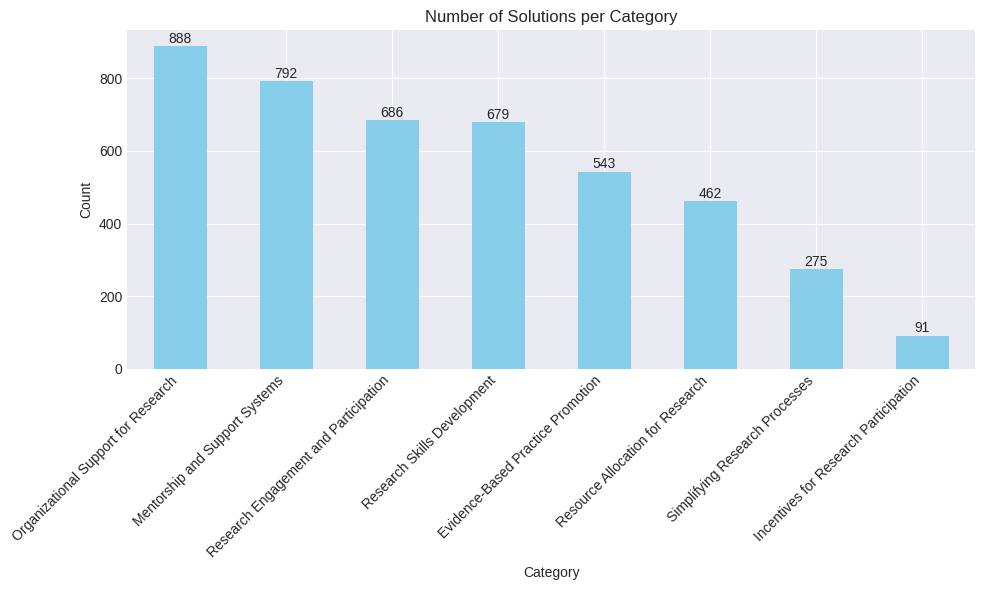

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

r = 0
all_mappings = []

# iterate over rows
for idx, row in df.iterrows():
    raw_solutions = row["all_solutions"]
    tuo = row["solution_categories_dict"]  # dict with {solution: category}

    # Convert both strings safely
    try:
        solutions_dict = ast.literal_eval(raw_solutions)
    except Exception as e:
        print(f"Error evaluating all_solutions at index {idx}: {e}")
        continue

    try:
        categories_dict = ast.literal_eval(tuo)
    except Exception as e:
        print(f"Error evaluating solution_categories_dict at index {idx}: {e}")
        continue

    # Loop through the solutions and find matching category from tuo
    if isinstance(solutions_dict, dict):
        for solution, value in solutions_dict.items():
            category = categories_dict.get(solution, "Unknown")  # fallback if not found
            r += 1
            all_mappings.append({"solution": solution, "category": category})
    elif isinstance(solutions_dict, list):
        for solution in solutions_dict:
            category = categories_dict.get(solution, "Unknown")
            r += 1
            all_mappings.append({"solution": solution, "category": category})

# Create a DataFrame
mapping_df = pd.DataFrame(all_mappings)

# Count categories
category_counts = mapping_df["category"].value_counts()
print(category_counts)

# Plot the bar chart
plt.figure(figsize=(10, 6))
ax = category_counts.plot(kind="bar", color="skyblue")
plt.title("Number of Solutions per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")

# Add count labels above bars
for i, v in enumerate(category_counts):
    ax.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


<Figure size 1200x700 with 0 Axes>

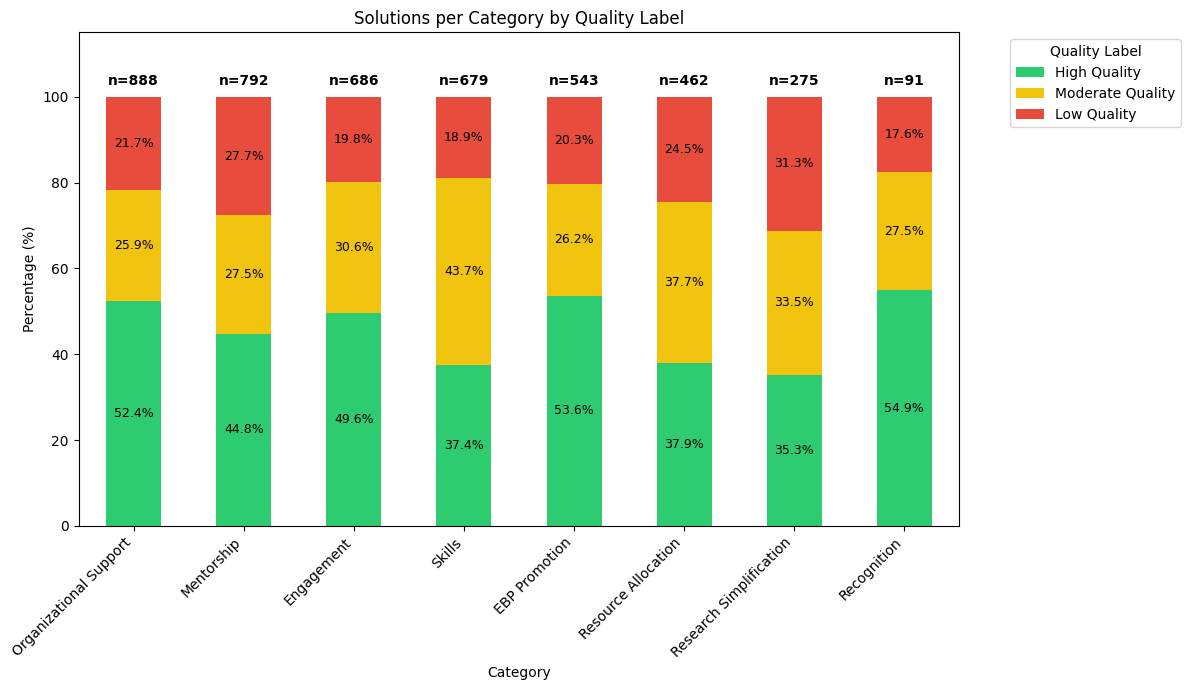

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# ✅ Mapping to abbreviated theme names
theme_abbrev_map = {
    'Research Skills Development': 'Skills',
    'Organizational Support for Research': 'Organizational Support',
    'Research Engagement and Participation': 'Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Resource Allocation',
    'Mentorship and Support Systems': 'Mentorship',
    'Simplifying Research Processes': 'Research Simplification',
    'Incentives for Research Participation': 'Recognition'
}

# ✅ Convert stringified dicts safely
df["solution_categories_dict"] = df["solution_categories_dict"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["all_solutions"] = df["all_solutions"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# ✅ Flatten solution → category mappings
all_mappings = []
for i, row in df.iterrows():
    solutions_dict = row["all_solutions"]
    categories_dict = row["solution_categories_dict"]

    if isinstance(solutions_dict, dict):
        for sol, val in solutions_dict.items():
            category = categories_dict.get(sol, "Unknown")
            all_mappings.append({"index": i, "solution": sol, "category": category})
    elif isinstance(solutions_dict, list):
        for sol in solutions_dict:
            category = categories_dict.get(sol, "Unknown")
            all_mappings.append({"index": i, "solution": sol, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# ✅ Merge with quality labels
mapping_df = mapping_df.merge(
    df_2[["quality_label"]],
    left_on="index", right_index=True, how="left"
)

# ✅ Apply abbreviated theme names
mapping_df["category"] = mapping_df["category"].map(theme_abbrev_map).fillna(mapping_df["category"])

# ✅ Count solutions per category/quality
stack_data = mapping_df.groupby(["category", "quality_label"]).size().unstack(fill_value=0)

# ✅ Save absolute counts
absolute_counts = stack_data.sum(axis=1)

# ✅ Normalize to %
stack_data_pct = stack_data.div(stack_data.sum(axis=1), axis=0) * 100

# ✅ Reorder columns (ensure consistent order)
cols = [col for col in ["High Quality", "Moderate Quality", "Low Quality"] if col in stack_data_pct.columns]
stack_data_pct = stack_data_pct[cols]

# ✅ Sort by total count
stack_data_pct = stack_data_pct.loc[absolute_counts.sort_values(ascending=False).index]
absolute_counts = absolute_counts.loc[stack_data_pct.index]

# ✅ Colors
color_map = {
    "High Quality": "#2ECC71",
    "Moderate Quality": "#F1C40F",
    "Low Quality": "#E74C3C"
}

# ✅ Plot
plt.figure(figsize=(12,7))
ax = stack_data_pct.plot(kind="bar", stacked=True,
                         color=[color_map[col] for col in stack_data_pct.columns],
                         figsize=(12,7))

plt.title("Solutions per Category by Quality Label")
plt.xlabel("Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")

plt.legend(title="Quality Label", bbox_to_anchor=(1.05, 1), loc="upper left")

# ✅ Add % labels inside bars
for idx, category in enumerate(stack_data_pct.index):
    y_offset = 0
    for label in stack_data_pct.columns:
        value = stack_data_pct.loc[category, label]
        if value > 0:
            ax.text(idx, y_offset + value/2, f"{value:.1f}%",
                    ha="center", va="center", fontsize=9)
            y_offset += value

# ✅ Add total counts above bars
for idx, total in enumerate(absolute_counts):
    ax.text(idx, 102, f"n={total}", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.ylim(0, 115)
plt.tight_layout()
plt.show()


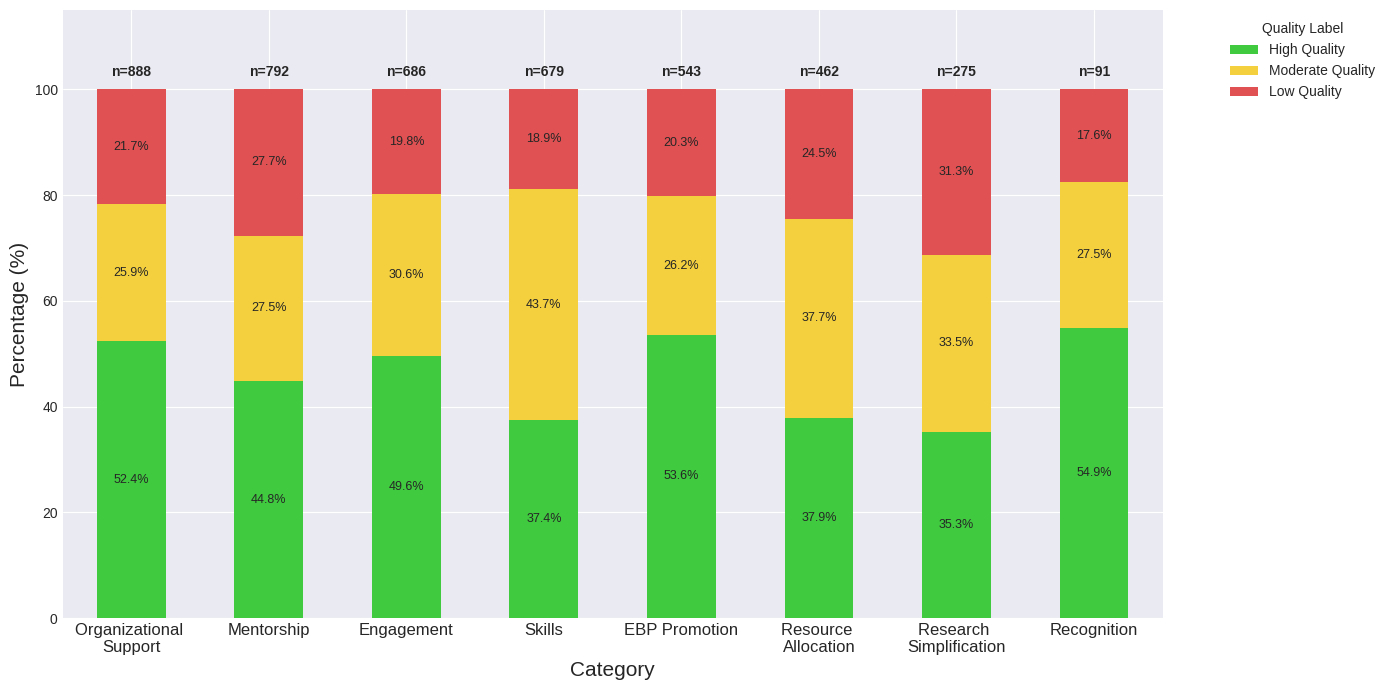

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast
import matplotlib.colors as mc
import colorsys

# -------------------------------------------------------
# Abbreviation mapping for solution categories
# -------------------------------------------------------
theme_abbrev_map = {
    'Research Skills Development': 'Skills',
    'Organizational Support for Research': 'Organizational \nSupport',
    'Research Engagement and Participation': 'Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Resource \nAllocation',
    'Mentorship and Support Systems': 'Mentorship',
    'Simplifying Research Processes': 'Research \nSimplification',
    'Incentives for Research Participation': 'Recognition'
}

# -------------------------------------------------------
# Convert stringified dicts to actual dicts
# -------------------------------------------------------
df["solution_categories_dict"] = df["solution_categories_dict"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["all_solutions"] = df["all_solutions"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# -------------------------------------------------------
# Flatten solution -> category mapping
# -------------------------------------------------------
all_mappings = []
for i, row in df.iterrows():
    solutions_dict = row["all_solutions"]
    categories_dict = row["solution_categories_dict"]

    if isinstance(solutions_dict, dict):
        for sol, val in solutions_dict.items():
            category = categories_dict.get(sol, "Unknown")
            all_mappings.append({"index": i, "solution": sol, "category": category})
    elif isinstance(solutions_dict, list):
        for sol in solutions_dict:
            category = categories_dict.get(sol, "Unknown")
            all_mappings.append({"index": i, "solution": sol, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# -------------------------------------------------------
# Merge with quality label
# -------------------------------------------------------
mapping_df = mapping_df.merge(
    df_2[["quality_label"]],
    left_on="index", right_index=True, how="left"
)

# -------------------------------------------------------
# Apply abbreviation map
# -------------------------------------------------------
mapping_df["category"] = mapping_df["category"].map(theme_abbrev_map).fillna(mapping_df["category"])

# -------------------------------------------------------
# Count by category and quality
# -------------------------------------------------------
stack_data = mapping_df.groupby(["category", "quality_label"]).size().unstack(fill_value=0)

# Save absolute counts
absolute_counts = stack_data.sum(axis=1)

# Normalize to %
stack_data_pct = stack_data.div(stack_data.sum(axis=1), axis=0) * 100

# Ensure correct quality column order
cols = [c for c in ["High Quality", "Moderate Quality", "Low Quality"] if c in stack_data_pct.columns]
stack_data_pct = stack_data_pct[cols]

# Sort by frequency
stack_data_pct = stack_data_pct.loc[absolute_counts.sort_values(ascending=False).index]
absolute_counts = absolute_counts.loc[stack_data_pct.index]

# -------------------------------------------------------
# Lighten function (for pastel colors)
# -------------------------------------------------------
def lighten(color, amount=0.8):
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    new_c = colorsys.hls_to_rgb(c[0], min(1, amount * c[1] + (1 - amount)), c[2])
    return new_c

tab10 = plt.cm.tab10

color_map = {
    "High Quality": lighten(tab10(2), 0.8),
    "Moderate Quality": lighten("#F1C40F", 0.8),
    "Low Quality": lighten(tab10(3), 0.8)
}

# -------------------------------------------------------
# Auto-multiline function (respects existing \n)
# -------------------------------------------------------
def split_label(label, max_words_per_line=2):
    if "\n" in label:   # respect manual line breaks
        return label
    words = label.split()
    lines = []
    for i in range(0, len(words), max_words_per_line):
        lines.append(" ".join(words[i:i+max_words_per_line]))
    return "\n".join(lines)

# -------------------------------------------------------
# Plot
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 7))

stack_data_pct.plot(
    kind="bar",
    stacked=True,
    color=[color_map[col] for col in stack_data_pct.columns],
    ax=ax
)

plt.xlabel("Category", fontsize=15)
plt.ylabel("Percentage (%)", fontsize=15)

# Apply multiline labels
new_labels = [split_label(cat) for cat in stack_data_pct.index]
ax.set_xticklabels(new_labels, rotation=0, ha="center", fontsize=12)

# Legend
plt.legend(title="Quality Label", bbox_to_anchor=(1.05, 1), loc="upper left")

# -------------------------------------------------------
# Add % inside bars
# -------------------------------------------------------
for idx, category in enumerate(stack_data_pct.index):
    y_offset = 0
    for label in stack_data_pct.columns:
        value = stack_data_pct.loc[category, label]
        if value > 0:
            ax.text(idx, y_offset + value/2, f"{value:.1f}%",
                    ha="center", va="center", fontsize=9)
        y_offset += value

# -------------------------------------------------------
# Add total counts above bars
# -------------------------------------------------------
for idx, total in enumerate(absolute_counts):
    ax.text(idx, 102, f"n={total}", ha='center',
            va='bottom', fontsize=10, fontweight="bold")

plt.ylim(0, 115)
plt.tight_layout()

plt.savefig("solutions.png", dpi=600, bbox_inches="tight")
plt.show()


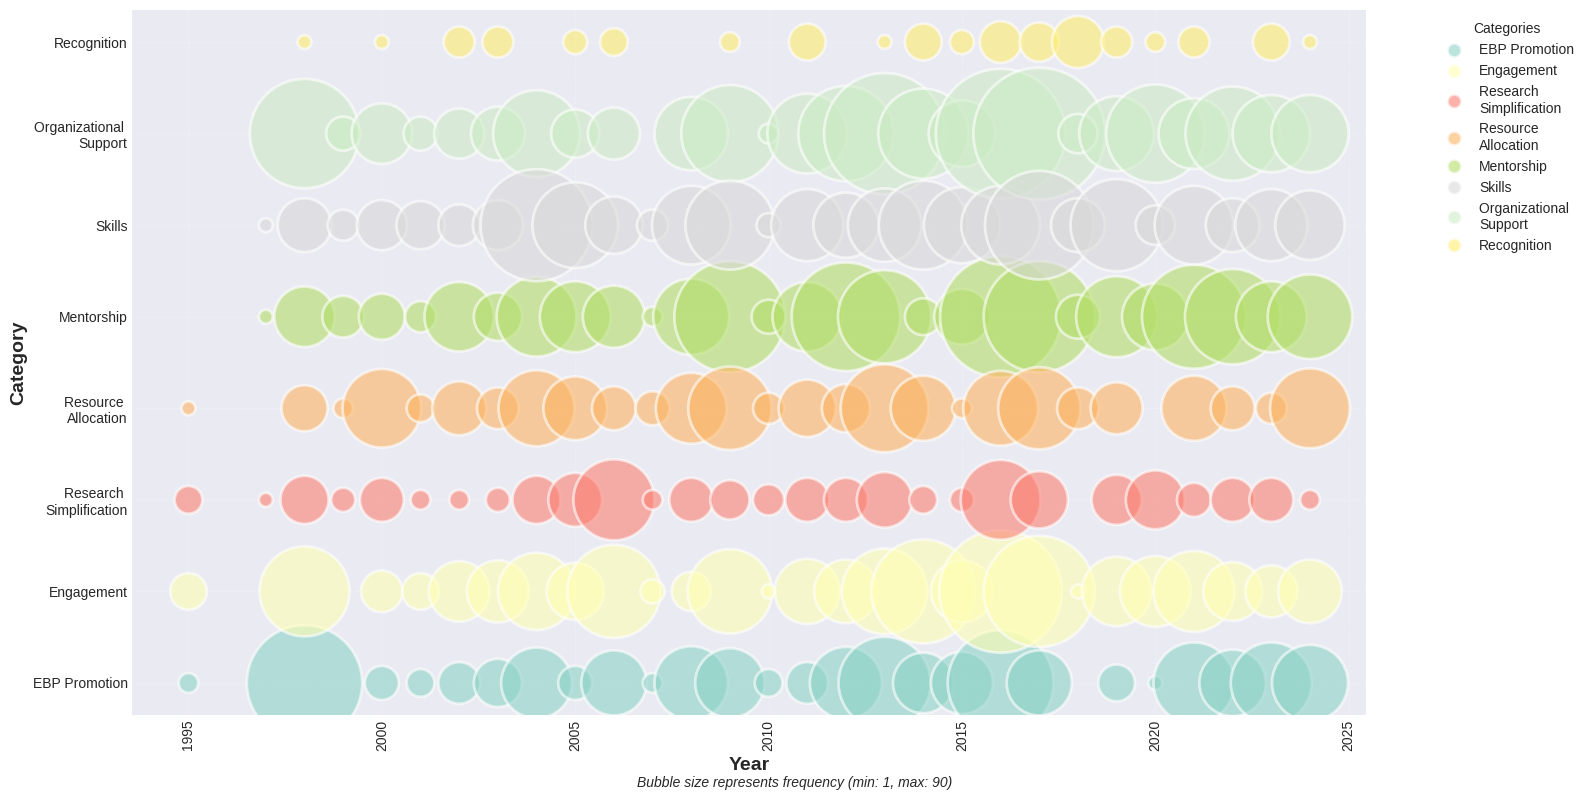

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

# ✅ Mapping to abbreviated theme names
theme_abbrev_map = {
    'Research Skills Development': 'Skills',
    'Organizational Support for Research': 'Organizational \nSupport',
    'Research Engagement and Participation': 'Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Resource \nAllocation',
    'Mentorship and Support Systems': 'Mentorship',
    'Simplifying Research Processes': 'Research \nSimplification',
    'Incentives for Research Participation': 'Recognition'
}

# ✅ Convert stringified dicts safely
df["solution_categories_dict"] = df["solution_categories_dict"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["all_solutions"] = df["all_solutions"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# ✅ Flatten solution → category mappings with Year
all_mappings = []
for i, row in df.iterrows():
    year = row.get("Year", None)
    solutions_dict = row["all_solutions"]
    categories_dict = row["solution_categories_dict"]

    if isinstance(solutions_dict, dict):
        for sol, val in solutions_dict.items():
            category = categories_dict.get(sol, "Unknown")
            all_mappings.append({"Year": year, "solution": sol, "category": category})
    elif isinstance(solutions_dict, list):
        for sol in solutions_dict:
            category = categories_dict.get(sol, "Unknown")
            all_mappings.append({"Year": year, "solution": sol, "category": category})

mapping_df = pd.DataFrame(all_mappings)

# ✅ Apply abbreviated theme names
mapping_df["category"] = mapping_df["category"].map(theme_abbrev_map).fillna(mapping_df["category"])

# ✨ Filter out 1984 BEFORE aggregation
mapping_df = mapping_df[mapping_df["Year"] != 1984]

# 🔵 Aggregate counts for bubble chart by Year and Category
bubble_df = mapping_df.groupby(["Year", "category"]).size().reset_index(name="count")

# Create figure with custom style
plt.style.use('seaborn-v0_8-darkgrid')
fig, ax = plt.subplots(figsize=(16, 8))

# Create color map for categories
categories = bubble_df["category"].unique()
colors = plt.cm.Set3(np.linspace(0, 1, len(categories)))
category_colors = dict(zip(categories, colors))

# Plot all bubbles
scatter = ax.scatter(
    bubble_df["Year"],
    bubble_df["category"],
    s=bubble_df["count"] * 100,
    alpha=0.6,
    c=[category_colors[cat] for cat in bubble_df["category"]],
    edgecolors='white',
    linewidth=2
)

# Customize the plot
# ax.set_title("Distribution of Solution Categories Over Time",
#              fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel("Year", fontsize=14, fontweight='bold')
ax.set_ylabel("Category", fontsize=14, fontweight='bold')

# Rotate x-axis labels
plt.xticks(rotation=90)

# Add grid for better readability
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax.set_axisbelow(True)

# Create legend with actual categories
legend_elements = [plt.Line2D([0], [0], marker='o', color='w',
                              markerfacecolor=category_colors[cat],
                              markersize=10, label=cat, alpha=0.6,
                              markeredgecolor='white', markeredgewidth=2)
                   for cat in categories]
ax.legend(handles=legend_elements, title='Categories',
          bbox_to_anchor=(1.05, 1), loc='upper left')

# Add size reference
min_count = int(bubble_df['count'].min())
max_count = int(bubble_df['count'].max())
# size_text = f"Bubble size represents frequency (min: {min_count}, max: {max_count})"
plt.figtext(0.5, 0.01, size_text, ha='center', fontsize=10, style='italic')

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
plt.show()



/tmp/ipython-input-2036636422.py:140: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels, fontsize=15, fontweight="500")


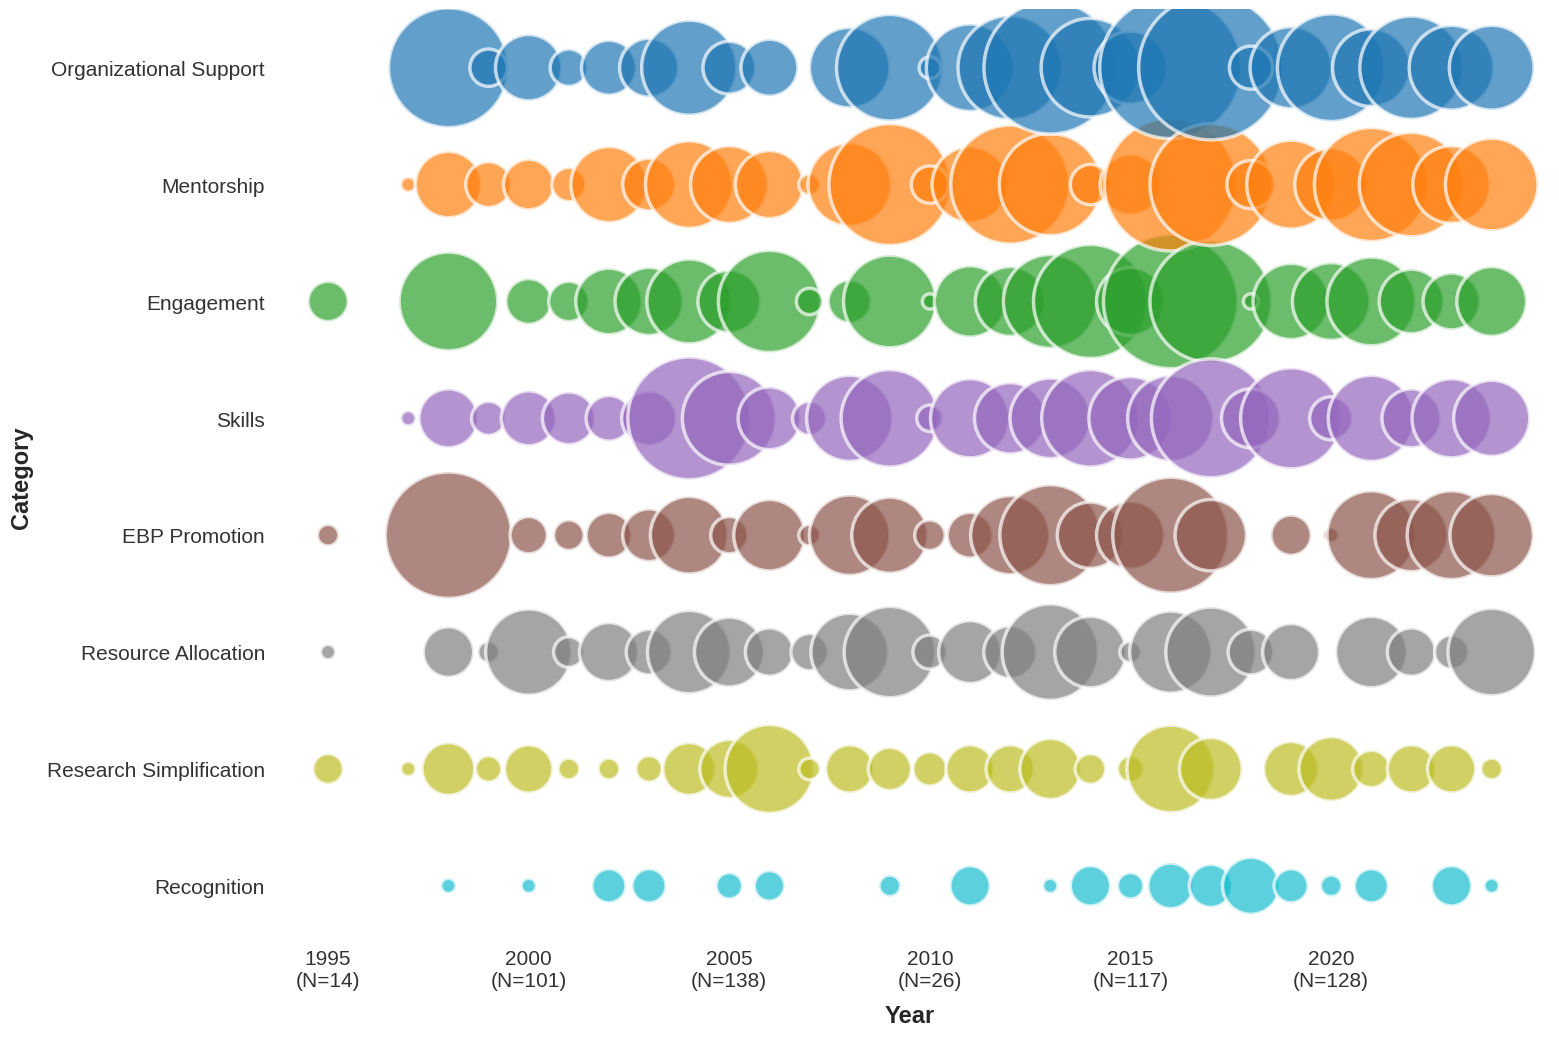

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

# -------------------------------------------------------
# Abbreviation mapping for solution categories
# -------------------------------------------------------
theme_abbrev_map = {
    'Research Skills Development': 'Skills',
    'Organizational Support for Research': 'Organizational Support',
    'Research Engagement and Participation': 'Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Resource Allocation',
    'Mentorship and Support Systems': 'Mentorship',
    'Simplifying Research Processes': 'Research Simplification',
    'Incentives for Research Participation': 'Recognition'
}

# -------------------------------------------------------
# Convert stringified dicts
# -------------------------------------------------------
df["solution_categories_dict"] = df["solution_categories_dict"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["all_solutions"] = df["all_solutions"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# -------------------------------------------------------
# Flatten solution → category + year
# -------------------------------------------------------
all_mappings = []
for i, row in df.iterrows():
    year = row["Year"]
    solutions_dict = row["all_solutions"]
    categories_dict = row["solution_categories_dict"]

    if isinstance(solutions_dict, dict):
        for sol, val in solutions_dict.items():
            cat = categories_dict.get(sol, "Unknown")
            all_mappings.append({"Year": year, "category": cat})

    elif isinstance(solutions_dict, list):
        for sol in solutions_dict:
            cat = categories_dict.get(sol, "Unknown")
            all_mappings.append({"Year": year, "category": cat})

mapping_df = pd.DataFrame(all_mappings)

# Apply short names
mapping_df["category"] = mapping_df["category"].map(theme_abbrev_map).fillna(mapping_df["category"])

# Remove bad year
mapping_df = mapping_df[mapping_df["Year"] != 1984]

# -------------------------------------------------------
# Define Y-axis order (TOP → BOTTOM) — same style as barriers
# -------------------------------------------------------
desired_order = [
    "Organizational Support",
    "Mentorship",
    "Engagement",
    "Skills",
    "EBP Promotion",
    "Resource Allocation",
    "Research Simplification",
    "Recognition"
]

# Map to numeric Y positions
category_to_position = {cat: len(desired_order) - 1 - i for i, cat in enumerate(desired_order)}
mapping_df["y_position"] = mapping_df["category"].map(category_to_position)

# -------------------------------------------------------
# Aggregate counts
# -------------------------------------------------------
bubble_df = mapping_df.groupby(["Year", "category", "y_position"]).size().reset_index(name="count")

# -------------------------------------------------------
# Plot — SAME CLEAN STYLE as barrier bubble chart
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 11))

# Clean white background
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Consistent colors (tab10)
base_colors = plt.cm.tab10(np.linspace(0, 1, len(desired_order)))
category_colors = dict(zip(desired_order, base_colors))

scatter = ax.scatter(
    bubble_df["Year"],
    bubble_df["y_position"],
    s=bubble_df["count"] * 120,
    alpha=0.7,
    c=[category_colors[c] for c in bubble_df["category"]],
    edgecolors="white",
    linewidth=2.5
)

# -------------------------------------------------------
# Y-axis labels
# -------------------------------------------------------
ax.set_yticks(range(len(desired_order)))
ax.set_yticklabels(list(reversed(desired_order)),
                   fontsize=14, fontweight="500")

# KEEP BUBBLES INSIDE PLOT
ax.set_ylim(-0.5, len(desired_order) - 0.5)

# -------------------------------------------------------
# Axis labels + styling
# -------------------------------------------------------
ax.set_xlabel("Year", fontsize=17, fontweight="bold", labelpad=10)
ax.set_ylabel("Category", fontsize=17, fontweight="bold", labelpad=10)

ax.tick_params(axis="both", labelsize=15, length=0, colors="#333333")

# No grid, no spines (clean)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# -------------------------------------------------------
# X labels: Year + (N=xx) — EXACT SAME STYLE AS BARRIERS
# -------------------------------------------------------
year_counts = bubble_df.groupby("Year")["count"].sum()

xticks = ax.get_xticks()
new_labels = []
for xtick in xticks:
    year = int(xtick)
    if year in year_counts.index:
        new_labels.append(f"{year}\n(N={year_counts.loc[year]})")
    else:
        new_labels.append("")

ax.set_xticklabels(new_labels, fontsize=15, fontweight="500")

# -------------------------------------------------------
# Final layout
# -------------------------------------------------------
plt.tight_layout()
plt.subplots_adjust(left=0.15, right=0.95, top=0.95, bottom=0.1)

plt.savefig("solution_time_series.png", dpi=600, bbox_inches="tight")
plt.show()


category
Mentorship and Support Systems           544
Organizational Support for Research      528
Research Engagement and Participation    481
Research Skills Development              407
Resource Allocation for Research         341
Evidence-Based Practice Promotion        335
Simplifying Research Processes           193
Incentives for Research Participation     64
Name: count, dtype: int64


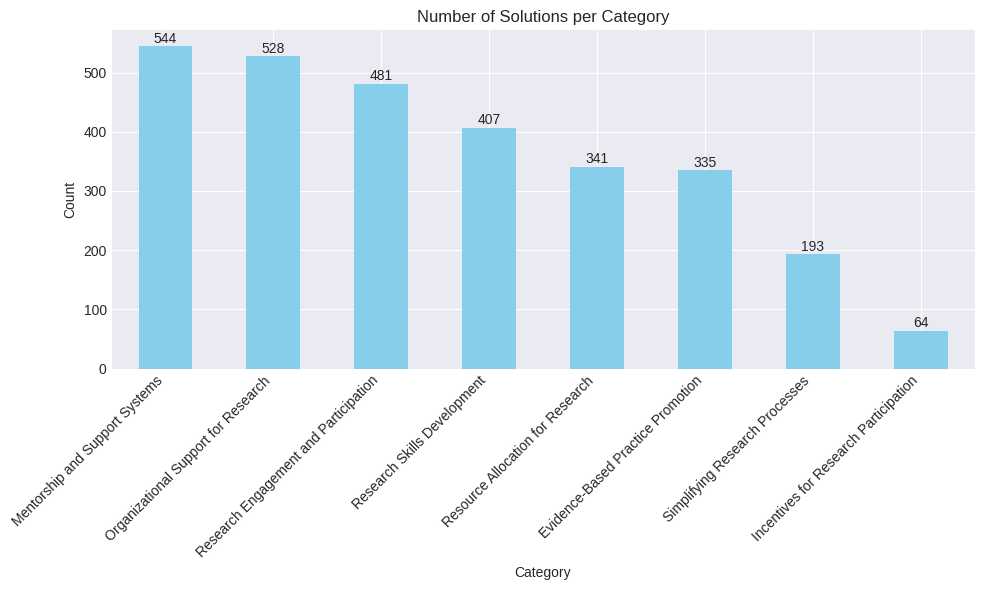

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import ast
r = 0
all_mappings = []
for row in df["solution_categories_dict"]:
    # Use ast.literal_eval to safely evaluate the string as a Python dictionary
    try:
        row_dict = ast.literal_eval(row)
    except (ValueError, SyntaxError) as e:
        print(f"Error evaluating string: {e}\nString: {row}")
        continue

    if isinstance(row_dict, dict):
        for solution, category in row_dict.items():
            r+=1
            all_mappings.append({"solution": solution, "category": category})

mapping_df = pd.DataFrame(all_mappings)

category_counts = mapping_df["category"].value_counts()

print(category_counts)

plt.figure(figsize=(10, 6))
ax = category_counts.plot(kind="bar", color="skyblue")
plt.title("Number of Solutions per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(category_counts):
    ax.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
print(mapping_df.head())
print(mapping_df.columns)


                                            solution  \
0  Access to reading material at nurses’ place of...   
1                               Scheduled study-time   
2  Opportunity to read research literature and se...   
3  provide facilities to accommodate a higher lev...   
4  ensure that facilities are provided for implem...   

                           category  
0  Resource Allocation for Research  
1       Research Skills Development  
2       Research Skills Development  
3  Resource Allocation for Research  
4  Resource Allocation for Research  
Index(['solution', 'category'], dtype='object')


category_short
Organizational Support     888
Mentorship Support         792
Research Engagement        686
Research Skills            679
EBP Promotion              543
Resource Allocation        462
Research Simplification    275
Research Incentives         91
Name: count, dtype: int64


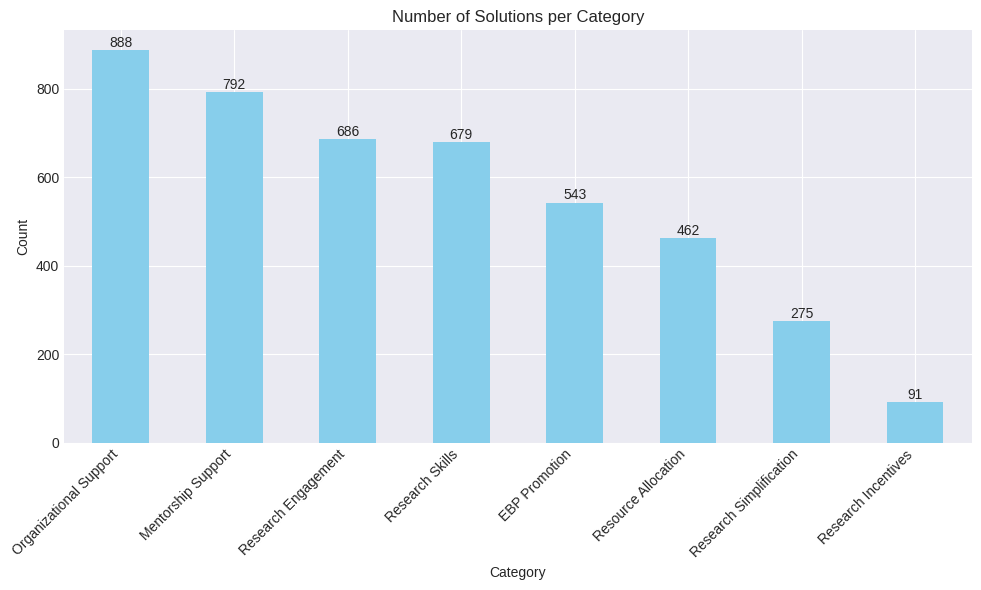

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# Mapping to abbreviated theme names
theme_abbrev_map = {
    'Research Skills Development': 'Research Skills',
    'Organizational Support for Research': 'Organizational Support',
    'Research Engagement and Participation': 'Research Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Resource Allocation',
    'Mentorship and Support Systems': 'Mentorship Support',
    'Simplifying Research Processes': 'Research Simplification',
    'Incentives for Research Participation': 'Research Incentives'
}

r = 0
all_mappings = []

# iterate over rows
for idx, row in df.iterrows():
    raw_solutions = row["all_solutions"]
    tuo = row["solution_categories_dict"]

    # safely convert both columns to Python dicts
    try:
        solutions_dict = ast.literal_eval(raw_solutions)
    except Exception as e:
        print(f"⚠️ Error evaluating all_solutions at index {idx}: {e}")
        continue

    try:
        categories_dict = ast.literal_eval(tuo)
    except Exception as e:
        print(f"⚠️ Error evaluating solution_categories_dict at index {idx}: {e}")
        continue

    # iterate through solutions and map to categories
    if isinstance(solutions_dict, dict):
        for solution in solutions_dict.keys():
            category = categories_dict.get(solution, "Unknown")
            short_name = theme_abbrev_map.get(category, category)
            r += 1
            all_mappings.append({
                "solution": solution,
                "category": category,
                "category_short": short_name
            })
    elif isinstance(solutions_dict, list):
        for solution in solutions_dict:
            category = categories_dict.get(solution, "Unknown")
            short_name = theme_abbrev_map.get(category, category)
            r += 1
            all_mappings.append({
                "solution": solution,
                "category": category,
                "category_short": short_name
            })

# Create a DataFrame
mapping_df = pd.DataFrame(all_mappings)

# Count by short category name
category_counts = mapping_df["category_short"].value_counts()
print(category_counts)

# Plot
plt.figure(figsize=(10, 6))
ax = category_counts.plot(kind="bar", color="skyblue")
plt.title("Number of Solutions per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")

# Add labels on bars
for i, v in enumerate(category_counts):
    ax.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


In [ ]:
mapping_df

,solution,category,category_short
0,Access to reading material at nurses’ place of...,Resource Allocation for Research,Resource Allocation
1,Scheduled study-time,Research Skills Development,Research Skills
2,Opportunity to read research literature and se...,Research Skills Development,Research Skills
3,provide facilities to accommodate a higher lev...,Resource Allocation for Research,Resource Allocation
4,ensure that facilities are provided for implem...,Resource Allocation for Research,Resource Allocation
...,...,...,...
4411,Encouragement of scientific events and forums ...,Research Engagement and Participation,Research Engagement
4412,"Valorization, motivation, and encouragement fr...",Organizational Support for Research,Organizational Support
4413,"Training in research, computer skills, and Int...",Research Skills Development,Research Skills
4414,Promote the culture of research and use of res...,Research Engagement and Participation,Research Engagement


heat map

In [ ]:
import ast

def safe_to_dict(val):
    if isinstance(val, dict):
        return val
    if isinstance(val, str):
        try:
            return ast.literal_eval(val)
        except Exception:
            return {}
    return {}

df["barrier_categories_dict"] = df["barrier_categories_dict"].apply(safe_to_dict)


In [ ]:
def clean_commas_from_dict(d):
    if not isinstance(d, dict):
        return d
    cleaned = {}
    for k, v in d.items():
        new_key = str(k).replace(",", "").strip()
        if isinstance(v, dict):
            new_value = clean_commas_from_dict(v)
        elif isinstance(v, list):
            new_value = [str(x).replace(",", "").strip() for x in v]
        else:
            new_value = str(v).replace(",", "").strip()
        cleaned[new_key] = new_value
    return cleaned

In [ ]:
def map_barrier_to_solution_categories(row):
    barrier_cats = row.get("barrier_categories_dict")
    barrier_solutions = row.get("barrier_solution_dict_cleaned")
    solution_cats = row.get("solution_categories_dict")

    barrier_cats = clean_commas_from_dict(row.get("barrier_categories_dict"))
    print("*"*50)

    print(len(barrier_cats.keys()))
    barrier_solutions = clean_commas_from_dict(row.get("barrier_solution_dict_cleaned"))
    solution_cats = clean_commas_from_dict(row.get("solution_categories_dict"))

    print(barrier_cats)
    print(barrier_solutions)
    print(solution_cats)
    print("-"*50)
    # print(barrier_cats)

    mapping = []
    i = 0
    for barrier in barrier_cats.keys():

        related_solutions = barrier_solutions[barrier]

        related_solution_categories = []

        if related_solutions:
          for sol in related_solutions:
              sol_cat = solution_cats.get(sol)
              if sol_cat:
                  related_solution_categories.append(sol_cat)
        else:
          i+=1

        mapping.append((barrier_cats[barrier],related_solution_categories))
    print(len(mapping))
    print(i)
    return mapping


from tqdm import tqdm
tqdm.pandas()

df["barrier_solution_category_map"] = df.progress_apply(map_barrier_to_solution_categories, axis=1)


In [ ]:
import pandas as pd
import json
import ast
from tqdm import tqdm

tqdm.pandas()


def safe_parse_dict(s):
    if isinstance(s, dict):
        return s

    if not isinstance(s, str):
        return None

    try:
        return json.loads(s)
    except:
        pass

    try:
        return ast.literal_eval(s)
    except:
        pass

    return None



df["barrier_categories_dict"] = df["barrier_categories_dict"].apply(safe_parse_dict)
df["barrier_solution_dict_cleaned"] = df["barrier_solution_dict_cleaned"].apply(safe_parse_dict)
df["solution_categories_dict"] = df["solution_categories_dict"].apply(safe_parse_dict)


def map_barrier_to_solution_categories(row):

    barrier_cats = row["barrier_categories_dict"]
    barrier_solutions = row["barrier_solution_dict_cleaned"]
    solution_cats = row["solution_categories_dict"]

    if not isinstance(barrier_cats, dict):
        return []
    if not isinstance(barrier_solutions, dict):
        return []
    if not isinstance(solution_cats, dict):
        return []

    mapping = []
    missing_solution_count = 0

    for barrier, barrier_cat in barrier_cats.items():

        related_solutions = barrier_solutions.get(barrier, [])

        related_solution_categories = []

        if related_solutions:
            for sol in related_solutions:
                sol_cat = solution_cats.get(sol)
                if sol_cat:
                    related_solution_categories.append(sol_cat)
        else:
            missing_solution_count += 1

        mapping.append((barrier_cat, related_solution_categories))

    return mapping



df["barrier_solution_category_map"] = df.progress_apply(
    map_barrier_to_solution_categories,
    axis=1
)

print("✔ Done! Created df['barrier_solution_category_map']")


100%|██████████| 122/122 [00:00<00:00, 8532.97it/s]

✔ Done! Created df['barrier_solution_category_map']


In [ ]:
import pandas as pd

rows = []
for _, r in df.iterrows():
    mapping = r["barrier_solution_category_map"]
    if isinstance(mapping, list):
        for barrier_cat, sol_cats in mapping:
            if sol_cats:
                for sol_cat in sol_cats:
                    rows.append({
                        "BarrierCategory": barrier_cat,
                        "SolutionCategory": sol_cat
                    })

flat_df = pd.DataFrame(rows)


In [ ]:
theme_abbrev_map = {
    'Research Skills Development': 'Skills',
    'Organizational Support for Research': 'Organizational \nSupport',
    'Research Engagement and Participation': 'Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Resource \nAllocation',
    'Mentorship and Support Systems': 'Mentorship',
    'Simplifying Research Processes': 'Research \nSimplification',
    'Incentives for Research Participation': 'Recognition'
}

In [ ]:
short_to_category = {
    "Culture & Organization": "Cultural and Organizational Issues",
    "Skills & Knowledge": "Skills and Knowledge Development",
    "Support & Collaboration": "Support and Collaboration",
    "Time & Workload": "Time and Workload Constraints",
    "Research Value": "Research Value and Relevance",
    "Information Overload": "Communication and Information Overload",
    "Access & Infrastructure": "Accessibility and Infrastructure",
    "Practice Gap": "Research Application and Practice Gap",
    "Resource Limitations": "Funding and Resource Limitations",
    "Adoption Resistance": "Implementation and Change Management"
}
category_to_short = {v: k for k, v in short_to_category.items()}


In [ ]:
flat_df["SolutionCategory"] = flat_df["SolutionCategory"].map(theme_abbrev_map)
flat_df["BarrierCategory"] = flat_df["BarrierCategory"].map(category_to_short)


In [ ]:
flat_df

,BarrierCategory,SolutionCategory
0,Time & Workload,Resource \nAllocation
1,Time & Workload,Skills
2,Time & Workload,Skills
3,Access & Infrastructure,Resource \nAllocation
4,Access & Infrastructure,Resource \nAllocation
...,...,...
4411,Culture & Organization,Engagement
4412,Culture & Organization,Organizational \nSupport
4413,Culture & Organization,Skills
4414,Culture & Organization,Engagement


In [ ]:
pivot = pd.pivot_table(
    flat_df,
    index="BarrierCategory",
    columns="SolutionCategory",
    aggfunc=len,
    fill_value=0
)

In [ ]:
print("Pivot shape:", pivot.shape)
print(pivot)
print(pivot.isna().sum().sum(), "NaN values")


Pivot shape: (10, 8)
SolutionCategory         EBP Promotion  Engagement  Mentorship  \
BarrierCategory                                                  
Access & Infrastructure             32          52          26   
Adoption Resistance                 29          17          27   
Culture & Organization             114         180         173   
Information Overload                57          53          32   
Practice Gap                        27          12           4   
Research Value                      37          33          11   
Resource Limitations                14          19          36   
Skills & Knowledge                 115         102         179   
Support & Collaboration             45         164         246   
Time & Workload                     73          54          58   

SolutionCategory         Organizational \nSupport  Recognition  \
BarrierCategory                                                  
Access & Infrastructure                        67     

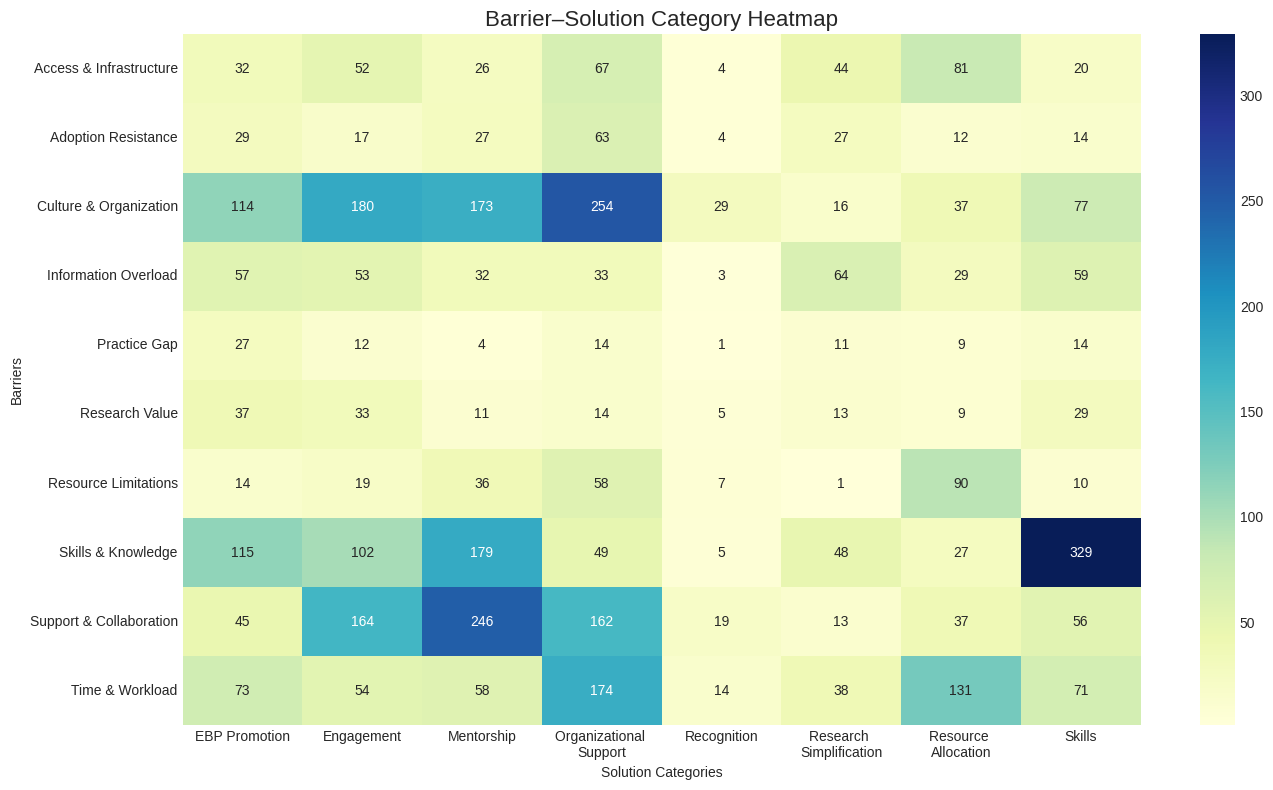

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))
sns.heatmap(pivot, cmap="YlGnBu", annot=True, fmt="d")
plt.title("Barrier–Solution Category Heatmap", fontsize=16)
plt.ylabel("Barriers")
plt.xlabel("Solution Categories")
plt.tight_layout()
plt.show()


<Axes: xlabel='SolutionCategory', ylabel='BarrierCategory'>

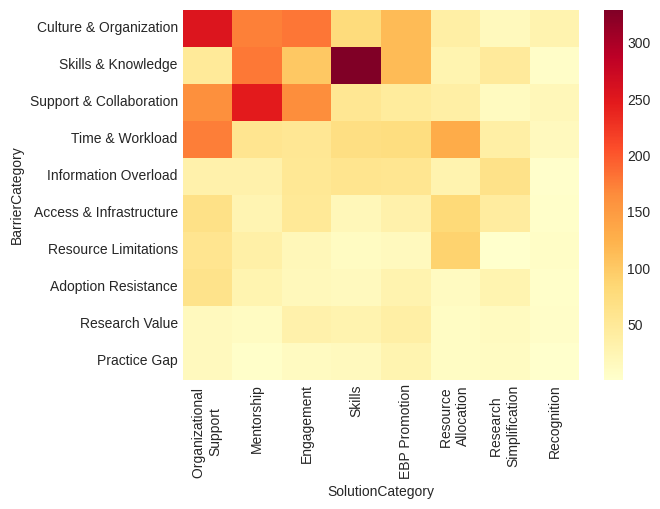

In [ ]:
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index,
                  pivot.sum(axis=0).sort_values(ascending=False).index]

sns.heatmap(pivot.iloc[:20, :20], cmap="YlOrRd", annot=False)


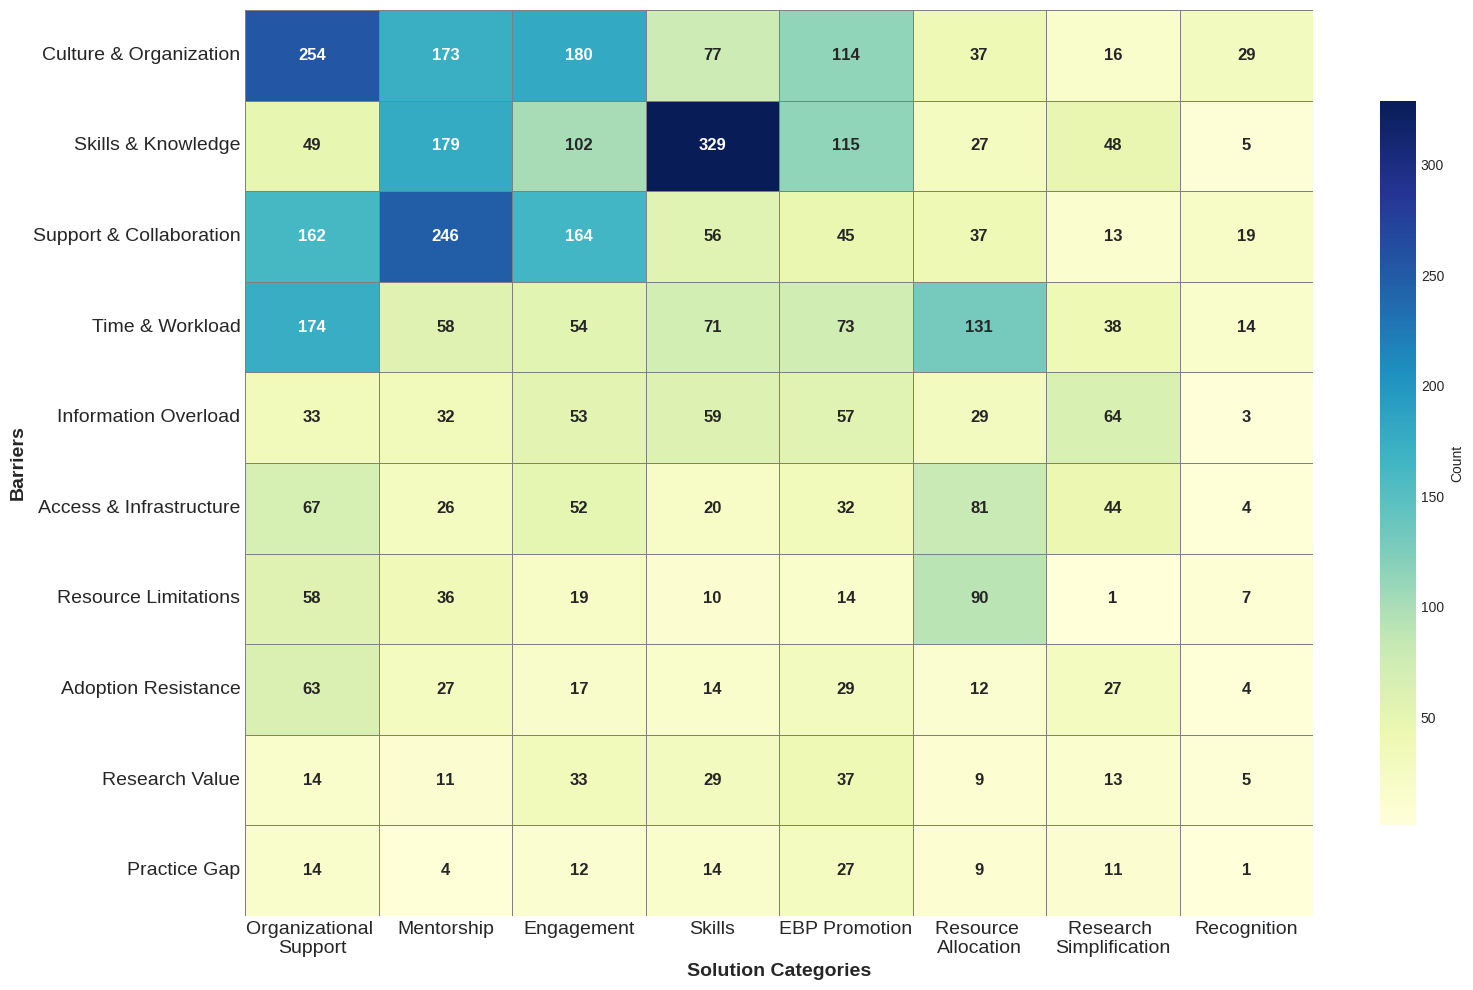

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

row_sums = pivot.sum(axis=1).sort_values(ascending=False)
col_sums = pivot.sum(axis=0).sort_values(ascending=False)
pivot_sorted = pivot.loc[row_sums.index, col_sums.index]

# pivot_sorted = pivot.sort_index(axis=0).sort_index(axis=1)


plt.figure(figsize=(16, 10))
ax = sns.heatmap(
    pivot_sorted,
    cmap="YlGnBu",
    annot=True,
    fmt="d",
    linewidths=0.5,
    linecolor='gray',
    cbar_kws={'label': 'Count', 'shrink': 0.8},
    annot_kws={'size': 12, 'weight': 'bold'}
)

# plt.title("Barrier–Solution Category Heatmap", fontsize=18, weight='bold', pad=20)
plt.ylabel("Barriers", fontsize=14, weight='bold')
plt.xlabel("Solution Categories", fontsize=14, weight='bold')

plt.xticks(rotation=0, ha='center', fontsize=14)

plt.yticks(rotation=0, fontsize=14)

plt.tight_layout()
plt.savefig("heat_map.png", dpi=600, bbox_inches="tight")

plt.show()

In [ ]:

import pandas as pd
import random
import json


sampled_df = df.sample(n=20, random_state=42)

pairs = []
for _, row in sampled_df.iterrows():
    d = row["solution_categories_dict"]

    if isinstance(d, str):
        try:
            d = json.loads(d.replace("'", '"'))
        except Exception as e:
            continue

    if isinstance(d, dict) and d:
        key = random.choice(list(d.keys()))
        value = d[key]
        pairs.append({
            "sol": key,
            "category": value
        })

pairs_df = pd.DataFrame(pairs)



In [ ]:
pairs_df.to_excel("/content/drive/MyDrive/fix_systematic_review/barriar_solution/sample_20_sol.xlsx", index=False)

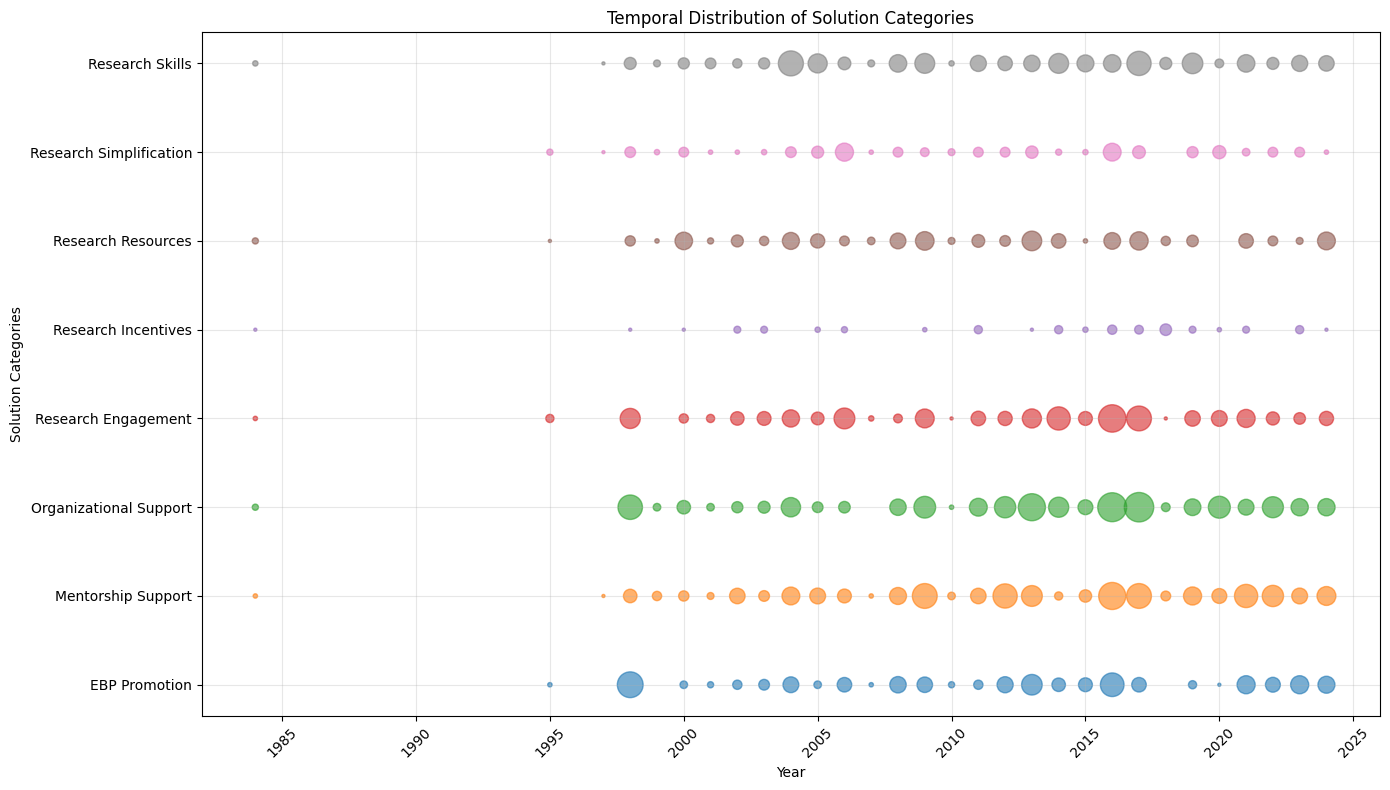

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# ✅ mapping to short category names
theme_abbrev_map = {
    'Research Skills Development': 'Research Skills',
    'Organizational Support for Research': 'Organizational Support',
    'Research Engagement and Participation': 'Research Engagement',
    'Evidence-Based Practice Promotion': 'EBP Promotion',
    'Resource Allocation for Research': 'Research Resources',
    'Mentorship and Support Systems': 'Mentorship Support',
    'Simplifying Research Processes': 'Research Simplification',
    'Incentives for Research Participation': 'Research Incentives'
}

# ✅ flatten solutions
all_mappings = []
for idx, row in df.iterrows():
    raw_solutions = row["all_solutions"]
    tuo = row["solution_categories_dict"]

    try:
        solutions_dict = ast.literal_eval(raw_solutions)
        categories_dict = ast.literal_eval(tuo)
    except Exception as e:
        continue

    if isinstance(solutions_dict, dict):
        for sol in solutions_dict.keys():
            category = categories_dict.get(sol, "Unknown")
            short_name = theme_abbrev_map.get(category, category)
            year = row.get("Year", None)
            all_mappings.append({"solution": sol, "category_short": short_name, "Year": year})
    elif isinstance(solutions_dict, list):
        for sol in solutions_dict:
            category = categories_dict.get(sol, "Unknown")
            short_name = theme_abbrev_map.get(category, category)
            year = row.get("Year", None)
            all_mappings.append({"solution": sol, "category_short": short_name, "Year": year})

mapping_df = pd.DataFrame(all_mappings)

# ✅ remove missing years or invalid entries
mapping_df = mapping_df.dropna(subset=["Year"])
mapping_df["Year"] = mapping_df["Year"].astype(int)

# ✅ aggregate counts per category per year
bubble_data = mapping_df.groupby(["category_short", "Year"]).size().reset_index(name="count")

# ✅ plot bubble chart
plt.figure(figsize=(14, 8))

categories = bubble_data["category_short"].unique()
colors = plt.cm.tab10.colors  # color palette

for i, cat in enumerate(categories):
    subset = bubble_data[bubble_data["category_short"] == cat]
    plt.scatter(
        subset["Year"],
        [cat] * len(subset),
        s=subset["count"] * 5,  # bubble size scale
        alpha=0.6,
        color=colors[i % len(colors)],
        label=cat
    )

plt.title("Temporal Distribution of Solution Categories")
plt.xlabel("Year")
plt.ylabel("Solution Categories")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
